# code_050 · Noisy and uncertain labels

**Book:** section 10.4. A self-contained data-cleaning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_10_GUIDE.md), [run evidence](../CHAPTER_10_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_050).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All data and calibration/measurement assumptions are simulated, without field safety, causal or universal cleaning claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1050;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1050


<a id="measurement"></a>
## The target definition and the label measurement are separate

Generate 700 independent components with latent severity s~Uniform(0,1); the reference binary target is s>=.5. Operational feature x=s+Normal(0,.25) is available at prediction. Two independent annotators observe a=s+Normal(0,.12) and b=s+Normal(0,.12), then threshold at .5. This is a measurement-error model for a binary finding, not validated damage grading. Split 400/150/150 components into training/development/final before fitting. Latent reference labels are used only for author-known diagnostics and final assessment, never to fit the predictive procedures.

The annotation-only posterior under a uniform [0,1] prior and the declared independent Gaussian errors is a truncated normal with mean (a+b)/2 and sd .12/sqrt(2). Its tail above .5 is a soft target q. This q conditions on annotation measurements, not on every available predictor. Using it as a training target does not automatically recover the optimal conditional risk given x; misspecified priors/error dependence can make it misleading. No Snorkel or learned label-aggregation model is implemented.


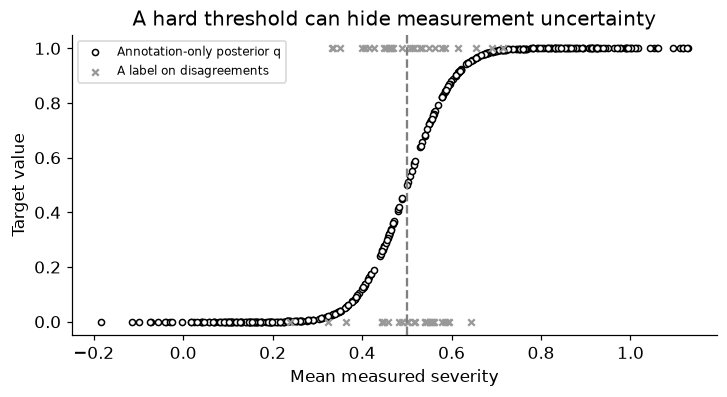

In [2]:
from scipy.special import ndtr,expit
N=700;s=rng.uniform(0,1,N);x=s+rng.normal(0,.25,N);a=s+rng.normal(0,.12,N);b=s+rng.normal(0,.12,N);hard_a=(a>=.5).astype(float);hard_b=(b>=.5).astype(float);gold=(s>=.5).astype(float)
tr=np.arange(400);dv=np.arange(400,550);te=np.arange(550,700);z=(a+b)/2;sd=.12/np.sqrt(2)
den=ndtr((1-z)/sd)-ndtr(-z/sd);assert np.all(den>1e-12)
q=np.clip((ndtr((1-z)/sd)-ndtr((.5-z)/sd))/den,0,1);agree=hard_a==hard_b
assert np.all((q>=0)&(q<=1)) and (~agree[tr]).any()
assert not set(tr)&set(te) and np.isfinite(q).all()
RESULTS['training_annotation_disagreement']=int((~agree[tr]).sum());RESULTS['training_consensus_cases']=int(agree[tr].sum());RESULTS['training_reference_accuracy']={'A':float((hard_a[tr]==gold[tr]).mean()),'B':float((hard_b[tr]==gold[tr]).mean())}
fig,ax=plt.subplots(figsize=(6.5,3.5));ax.scatter(z[tr],q[tr],s=16,facecolors='white',edgecolors='black',label='Annotation-only posterior q');ax.scatter(z[tr][~agree[tr]],hard_a[tr][~agree[tr]],s=18,marker='x',color='.6',label='A label on disagreements');ax.axvline(.5,color='.5',ls='--');ax.set(xlabel='Mean measured severity',ylabel='Target value',title='A hard threshold can hide measurement uncertainty');ax.legend(fontsize=8);plt.show()


<a id="adjudication"></a>
## Spend new reference evidence only on training disputes

Select up to twenty training disagreements closest to the threshold using the observed annotation mean. A new high-precision measurement s+Normal(0,.01) supplies an adjudicated hard label for those cases. This is extra simulated evidence, not a free algorithmic improvement and not access to final truth. Preserve original annotations, review indices and the new measurement. The real adjudication process would need its own authority, timing and quality checks.


In [3]:
disputed=tr[~agree[tr]];review=disputed[np.argsort(abs(z[disputed]-.5))[:20]]
adjudicated=hard_a.copy();reference_measurement=s[review]+rng.normal(0,.01,len(review));adjudicated[review]=(reference_measurement>=.5).astype(float)
assert len(review)==20 and set(review)<=set(tr) and not set(review)&set(te)
assert np.array_equal(adjudicated[dv],hard_a[dv]) and np.array_equal(adjudicated[te],hard_a[te])
RESULTS['new_training_adjudications']=len(review);RESULTS['adjudicated_labels_changed']=int((adjudicated[review]!=hard_a[review]).sum())


<a id="objectives"></a>
## Fit disclosed objectives without a hidden candidate search

Compare four predeclared targets/policies: annotator A hard labels; exclude A/B disagreements and retain their common hard label; keep all training cases with posterior soft targets; replace twenty A labels using adjudication. The exclusion changes the training population and all four policies have different evidence meanings. A fifth baseline predicts the A-training positive frequency. Standardize x with training statistics only, then fit each two-parameter logistic model using 600 full-gradient updates, rate .2 and L2=.01 on the slope only. No hyperparameter or label-policy selection occurs; development metrics are diagnostics, and every fixed procedure is retained for final assessment.

For targets t in [0,1], optimize mean log(1+exp(eta))-t*eta plus .5*.01*w_slope². Soft cross-entropy expresses that specified fractional target; it is not a general noise-robust loss or proof the label model is correct.


In [4]:
mean=float(x[tr].mean());scale=float(x[tr].std());X=np.column_stack([np.ones(N),(x-mean)/scale]);assert scale>0 and np.isclose(X[tr,1].mean(),0)
def objective(w,ix,target):
 eta=X[ix]@w;return float(np.mean(np.logaddexp(0,eta)-target*eta)+.005*w[1]**2)
def fit(ix,target):
 w=np.zeros(2);initial=objective(w,ix,target)
 for _ in range(600):
  gradient=X[ix].T@(expit(X[ix]@w)-target)/len(ix)+np.array([0,.01*w[1]]);w-=.2*gradient
 assert np.isfinite(w).all() and objective(w,ix,target)<=initial
 return w
policies={'hard_A':(tr,hard_a[tr]),'agreement_only':(tr[agree[tr]],hard_a[tr][agree[tr]]),'soft_posterior':(tr,q[tr]),'adjudicated':(tr,adjudicated[tr])}
models={name:fit(ix,target) for name,(ix,target) in policies.items()};constant=float(hard_a[tr].mean())
def logloss(labels,probs):
 probs=np.clip(probs,1e-12,1-1e-12);return float(-np.mean(labels*np.log(probs)+(1-labels)*np.log1p(-probs)))
RESULTS['training_cases_by_policy']={name:len(ix) for name,(ix,_) in policies.items()};RESULTS['development_noisy_A_logloss']={name:logloss(hard_a[dv],expit(X[dv]@w)) for name,w in models.items()}
assert all(len(w)==2 for w in models.values())


<a id="final"></a>
## Compare against the same independent reference target

After all policies and coefficients are fixed, open the 150 final reference targets defined by latent severity. Plot probability curves as functions of the available feature and report reference log loss/Brier error for every policy and the fixed baseline. This distinguishes a model's probability from annotation-only q and from the latent reference. The simulator privileges its author with reference truth; real disputes require reliable reference collection rather than an assumed gold column.


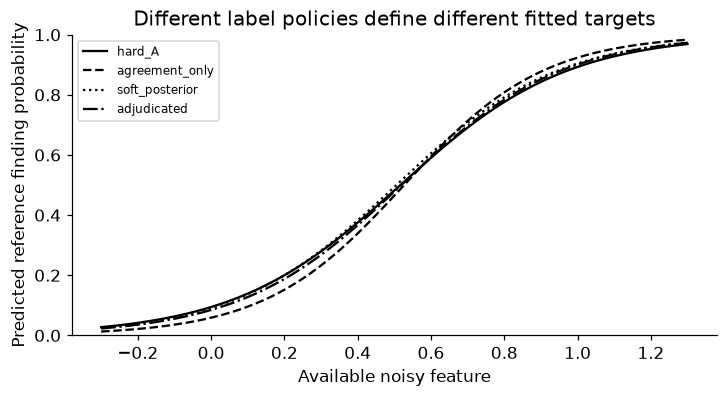

In [5]:
pred={name:expit(X[te]@w) for name,w in models.items()};pred['frequency']=np.full(len(te),constant)
metrics={name:{'log_loss':logloss(gold[te],v),'Brier':float(np.mean((gold[te]-v)**2))} for name,v in pred.items()}
assert all(np.isfinite(list(v.values())).all() for v in metrics.values()) and all(v.shape==(150,) for v in pred.values())
xx=np.linspace(-.3,1.3,150);XX=np.column_stack([np.ones(150),(xx-mean)/scale]);fig,ax=plt.subplots(figsize=(6.5,3.5))
for (name,w),style in zip(models.items(),['-','--',':','-.']):ax.plot(xx,expit(XX@w),color='black',ls=style,label=name)
ax.set(xlabel='Available noisy feature',ylabel='Predicted reference finding probability',ylim=(0,1),title='Different label policies define different fitted targets');ax.legend(fontsize=8);plt.show()
RESULTS['final_reference_metrics']=metrics;RESULTS['final_reference_cases']=len(te)


<a id="exercises"></a>
## Exercises and hints

1. Correlate annotation errors or change the prior; examine how an apparently precise q can become wrong.
2. Exclude disagreements concentrated near the real decision boundary and describe the changed training support.
3. Compare adjudication with another use of the same twenty-measurement budget on fresh final cases.
4. Define an ordinal damage-grade target and preserve threshold/ambiguity provenance instead of silently binarizing it.

**Hints:** disagreement is evidence about measurement, not a diagnosis of which annotator is correct. A weak heuristic, abstention, human grade and verified outcome have different roles. The primary [Snorkel paper](https://arxiv.org/abs/1711.10160) motivates modelling weak sources and dependencies; this explicit measurement model is not a reproduction of that system.


In [6]:
summary={'example_id':'code_050','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['continuous severity and threshold ambiguity', 'annotator disagreement and exclusion', 'explicit measurement-model soft targets', 'training-only adjudication and extra evidence budget', 'fixed logistic objectives and independent reference assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["continuous severity and threshold ambiguity", "annotator disagreement and exclusion", "explicit measurement-model soft targets", "training-only adjudication and extra evidence budget", "fixed logistic objectives and independent reference assessment"], "elapsed_seconds": 0.154, "example_id": "code_050", "hardware": "Darwin arm64 CPU", "results": {"adjudicated_labels_changed": 11, "development_noisy_A_logloss": {"adjudicated": 0.5108691467371568, "agreement_only": 0.5164861684550601, "hard_A": 0.5102147582194603, "soft_posterior": 0.5101360599447783}, "final_reference_cases": 150, "final_reference_metrics": {"adjudicated": {"Brier": 0.12624093749137233, "log_loss": 0.3918600896111478}, "agreement_only": {"Brier": 0.1263804647219115, "log_loss": 0.38789195559905904}, "frequency": {"Brier": 0.24960624999999997, "log_loss": 0.692359483935645}, "hard_A": {"Brier": 0.1264807756768904, "log_loss": 0.39424201015057203}, "soft_posterior": {"Brie